# 02 — Modélisation : tester des modèles et choisir le meilleur

**Démarche**
1. Préparer les données avec le pipeline défini après l'EDA.
2. Comparer 6 modèles en validation croisée stratifiée (5 plis) sur le **train**.
3. Optimiser les hyperparamètres des candidats.
4. Choisir le modèle selon 4 critères : performance, stabilité, temps, interprétabilité.
5. Ajuster le seuil de décision.
6. Évaluer **une seule fois** sur le **test**, interpréter et analyser l'équité.

**Métrique principale : ROC-AUC.** Elle mesure la capacité du modèle à classer un individu >50K
au-dessus d'un individu <=50K, indépendamment du seuil et du déséquilibre des classes.
On regarde aussi F1 et PR-AUC, plus centrées sur la classe minoritaire.

In [1]:
import sys
from pathlib import Path

# Permet d'importer le package src depuis le dossier notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import FIGURES_DIR

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """Enregistre la figure dans reports/figures/ pour la présentation."""
    fig.savefig(FIGURES_DIR / name, dpi=120, bbox_inches="tight")

In [2]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from src.config import RANDOM_STATE, SENSITIVE_FEATURES
from src.data.load_data import load_train_test, split_X_y
from src.models.evaluate import (best_threshold, compute_metrics, cross_validate_models,
                                   fairness_report, permutation_importance_df, plot_confusion,
                                   plot_cv_comparison, plot_importance, plot_pr_curves,
                                   plot_roc_curves)
from src.features.build_features import build_preprocessor
from src.models.models import PARAM_DISTRIBUTIONS, get_pipelines, save_model, tune

# FAST = True pour tester rapidement que tout tourne ; False pour les vrais résultats.
FAST = False
N_ITER, CV = (3, 3) if FAST else (20, 5)

train, test = load_train_test()
X_train, y_train = split_X_y(train)
X_test, y_test = split_X_y(test)
print(f"Train : {X_train.shape} | Test : {X_test.shape}")
print(f"Taux de >50K — train : {y_train.mean():.1%} | test : {y_test.mean():.1%}")

Train : (32561, 14) | Test : (16281, 14)
Taux de >50K — train : 24.1% | test : 23.6%


## 1. Le preprocessing

Le preprocessing est un `ColumnTransformer` scikit-learn placé **dans** chaque pipeline de modèle :
il est réappris sur les plis d'entraînement à chaque itération de la validation croisée,
ce qui évite toute fuite d'information du jeu de validation.

In [3]:
prep = build_preprocessor().fit(X_train)
names = prep.get_feature_names_out()
print(f"{X_train.shape[1]} colonnes brutes -> {len(names)} variables après preprocessing")
pd.DataFrame(prep.transform(X_train.head()), columns=names).round(2)

14 colonnes brutes -> 49 variables après preprocessing


,age,education-num,hours-per-week,capital-gain,capital-loss,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_infrequent_sklearn,marital-status_Divorced,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,...,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Female,sex_Male,native-country_Mexico,native-country_Philippines,native-country_United-States,native-country_infrequent_sklearn
0,0.03,1.13,-0.04,2.83,-0.22,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.84,1.13,-2.22,-0.30,-0.22,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.04,-0.42,-0.04,-0.30,-0.22,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
3,1.06,-1.20,-0.04,-0.30,-0.22,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,-0.78,1.13,-0.04,-0.30,-0.22,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


## 2. Comparaison des modèles (hyperparamètres par défaut)

| Modèle | Pourquoi le tester |
|---|---|
| Baseline (classe majoritaire) | Le score minimum à battre |
| Régression logistique | Modèle linéaire simple, rapide, coefficients interprétables |
| Arbre de décision | Non linéaire et lisible, mais instable / surapprend facilement |
| KNN | Approche par similarité, sans apprentissage de paramètres |
| Random Forest | Moyenne de nombreux arbres : réduit la variance |
| Gradient Boosting | Arbres construits pour corriger les erreurs des précédents : souvent le meilleur sur données tabulaires |

In [4]:
cv_default = cross_validate_models(get_pipelines(), X_train, y_train, cv=CV)
cols = ["modele", "roc_auc_mean", "roc_auc_std", "f1_mean", "pr_auc_mean", "accuracy_mean", "fit_time_s"]
cv_default[cols].round(4)

,modele,roc_auc_mean,roc_auc_std,f1_mean,pr_auc_mean,accuracy_mean,fit_time_s
0,Gradient Boosting,0.9280,0.0017,0.7135,0.8289,0.8729,0.9782
1,Random Forest,0.9184,0.0024,0.6927,0.8070,0.8653,1.7263
2,Arbre de décision,0.9038,0.0026,0.6450,0.7604,0.8561,0.1728
3,Régression logistique,0.8984,0.0024,0.6458,0.7371,0.8444,0.2048
4,KNN,0.8983,0.0027,0.6664,0.7316,0.8468,0.1322
5,Baseline (majoritaire),0.5000,0.0000,0.0000,0.2408,0.7592,0.2051


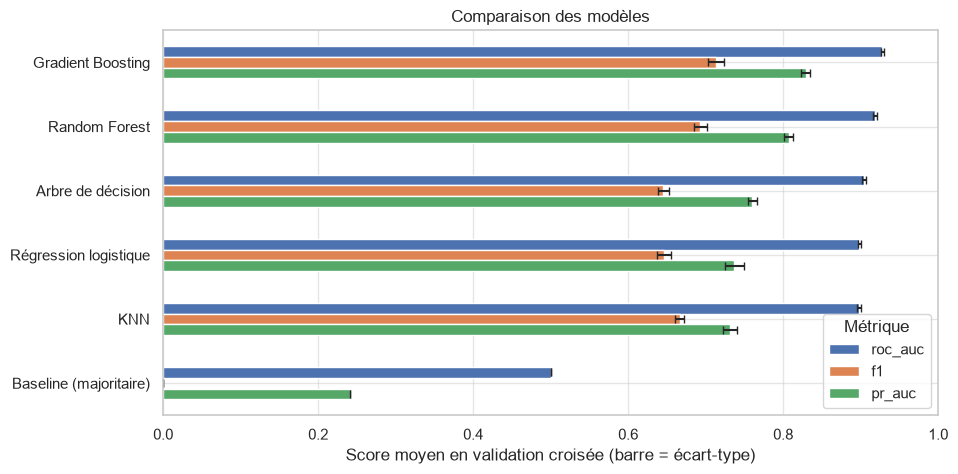

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_cv_comparison(cv_default, ax=ax)
save(fig, "model_cv_comparison.png")

**Lecture**
- La baseline a une accuracy de 0,759 mais un F1 nul et une ROC-AUC de 0,5 : elle confirme que
  l'accuracy seule ne suffit pas.
- Tous les modèles battent nettement la baseline (ROC-AUC entre 0,898 et 0,928).
- Les méthodes d'ensemble sont en tête : **Gradient Boosting (0,928)**, puis Random Forest (0,918).
- La régression logistique et KNN (0,898) sont derrière l'arbre de décision seul (0,904) :
  les relations sont non linéaires (âge, interactions statut marital × éducation), ce qu'un
  modèle linéaire capte mal.
- Les écarts-types entre plis sont très faibles (< 0,003) : le classement est fiable.

## 3. Optimisation des hyperparamètres

`RandomizedSearchCV` : on tire au hasard `N_ITER` combinaisons dans un espace de recherche
et on garde celle qui maximise la ROC-AUC en validation croisée.
Plus efficace qu'une grille complète pour un temps de calcul limité.

In [6]:
searches, rows = {}, []
for name in PARAM_DISTRIBUTIONS:
    search = tune(name, X_train, y_train, n_iter=N_ITER, cv=CV)
    searches[name] = search
    i = search.best_index_
    rows.append({"modele": name,
                 "roc_auc_defaut": cv_default.set_index("modele").loc[name, "roc_auc_mean"],
                 "roc_auc_tune": search.best_score_,
                 "roc_auc_std": search.cv_results_["std_test_score"][i],
                 "fit_time_s": search.cv_results_["mean_fit_time"][i]})
    print(f"{name:25s} -> {search.best_params_}")

cv_tuned = pd.DataFrame(rows).sort_values("roc_auc_tune", ascending=False).reset_index(drop=True)
cv_tuned["gain"] = cv_tuned["roc_auc_tune"] - cv_tuned["roc_auc_defaut"]
cv_tuned.round(4)

/Users/silviogangi/M2_SIAD/MLOPS/.venv/lib/python3.13/site-packages/sklearn/model_selection/_search.py:327: UserWarning: The total space of parameters 14 is smaller than n_iter=20. Running 14 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Régression logistique     -> {'model__class_weight': 'balanced', 'model__C': 3}
Arbre de décision         -> {'model__min_samples_leaf': 10, 'model__max_depth': 8, 'model__criterion': 'gini'}
Random Forest             -> {'model__n_estimators': 200, 'model__min_samples_leaf': 2, 'model__max_features': 0.3, 'model__max_depth': 15}
Gradient Boosting         -> {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 15, 'model__max_iter': 200, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.1}


,modele,roc_auc_defaut,roc_auc_tune,roc_auc_std,fit_time_s,gain
0,Gradient Boosting,0.9280,0.9289,0.0015,2.5172,0.0009
1,Random Forest,0.9184,0.9201,0.0020,4.5831,0.0018
2,Arbre de décision,0.9038,0.9069,0.0026,0.3552,0.0031
3,Régression logistique,0.8984,0.8985,0.0028,0.3201,0.0001


## 4. Choix du modèle

On choisit selon **4 critères** :
1. **Performance** : ROC-AUC moyenne en validation croisée (critère principal).
2. **Stabilité** : écart-type faible entre les plis.
3. **Coût** : temps d'entraînement et de prédiction.
4. **Interprétabilité** : peut-on expliquer les décisions ?

In [7]:
best_name = cv_tuned.loc[0, "modele"]
best_model = searches[best_name].best_estimator_
print(f"Modèle retenu : {best_name}")
print(f"ROC-AUC CV = {cv_tuned.loc[0, 'roc_auc_tune']:.4f} ± {cv_tuned.loc[0, 'roc_auc_std']:.4f}")
print("Hyperparamètres :", searches[best_name].best_params_)

Modèle retenu : Gradient Boosting
ROC-AUC CV = 0.9289 ± 0.0015
Hyperparamètres : {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 15, 'model__max_iter': 200, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.1}


## 5. Ajustement du seuil de décision

Par défaut, un modèle prédit `>50K` si la probabilité dépasse 0,5. Avec des classes
déséquilibrées, ce seuil n'est pas forcément le meilleur. On cherche le seuil qui
maximise le F1, **à partir de prédictions hors échantillon sur le train**
(`cross_val_predict`) : le test reste intact.

In [8]:
oof = cross_val_predict(best_model, X_train, y_train, method="predict_proba", n_jobs=-1,
                        cv=StratifiedKFold(CV, shuffle=True, random_state=RANDOM_STATE))[:, 1]
threshold, f1_oof = best_threshold(y_train, oof)
print(f"Seuil optimal : {threshold:.3f} (F1 hors échantillon : {f1_oof:.4f})")
print(f"F1 avec le seuil 0,5 : {compute_metrics(y_train, (oof >= 0.5).astype(int), oof)['f1']:.4f}")

Seuil optimal : 0.423 (F1 hors échantillon : 0.7328)
F1 avec le seuil 0,5 : 0.7157


## 6. Évaluation finale sur le jeu de test

C'est la **seule** fois où le jeu de test est utilisé. Ses scores estiment la performance
du modèle sur des données nouvelles.

In [9]:
test_scores = {n: s.best_estimator_.predict_proba(X_test)[:, 1] for n, s in searches.items()}
y_score = test_scores[best_name]
y_pred = (y_score >= threshold).astype(int)

all_models = pd.DataFrame({n: compute_metrics(y_test, (s >= 0.5).astype(int), s)
                           for n, s in test_scores.items()}).T
print("Tous les modèles tunés, seuil 0,5 :")
display(all_models.round(4))

final = pd.DataFrame({
    "seuil 0,5": compute_metrics(y_test, (y_score >= 0.5).astype(int), y_score),
    f"seuil {threshold:.2f}": compute_metrics(y_test, y_pred, y_score),
}).T
print(f"\n{best_name} :")
final.round(4)

Tous les modèles tunés, seuil 0,5 :


,accuracy,precision,recall,f1,roc_auc,pr_auc
Régression logistique,0.8001,0.5506,0.8378,0.6645,0.8966,0.7278
Arbre de décision,0.8577,0.7954,0.5356,0.6401,0.9053,0.7611
Random Forest,0.8672,0.7872,0.6001,0.6810,0.9173,0.8063
Gradient Boosting,0.8727,0.7734,0.6524,0.7078,0.9270,0.8246



Gradient Boosting :


,accuracy,precision,recall,f1,roc_auc,pr_auc
"seuil 0,5",0.8727,0.7734,0.6524,0.7078,0.927,0.8246
seuil 0.42,0.8679,0.7237,0.7129,0.7183,0.927,0.8246


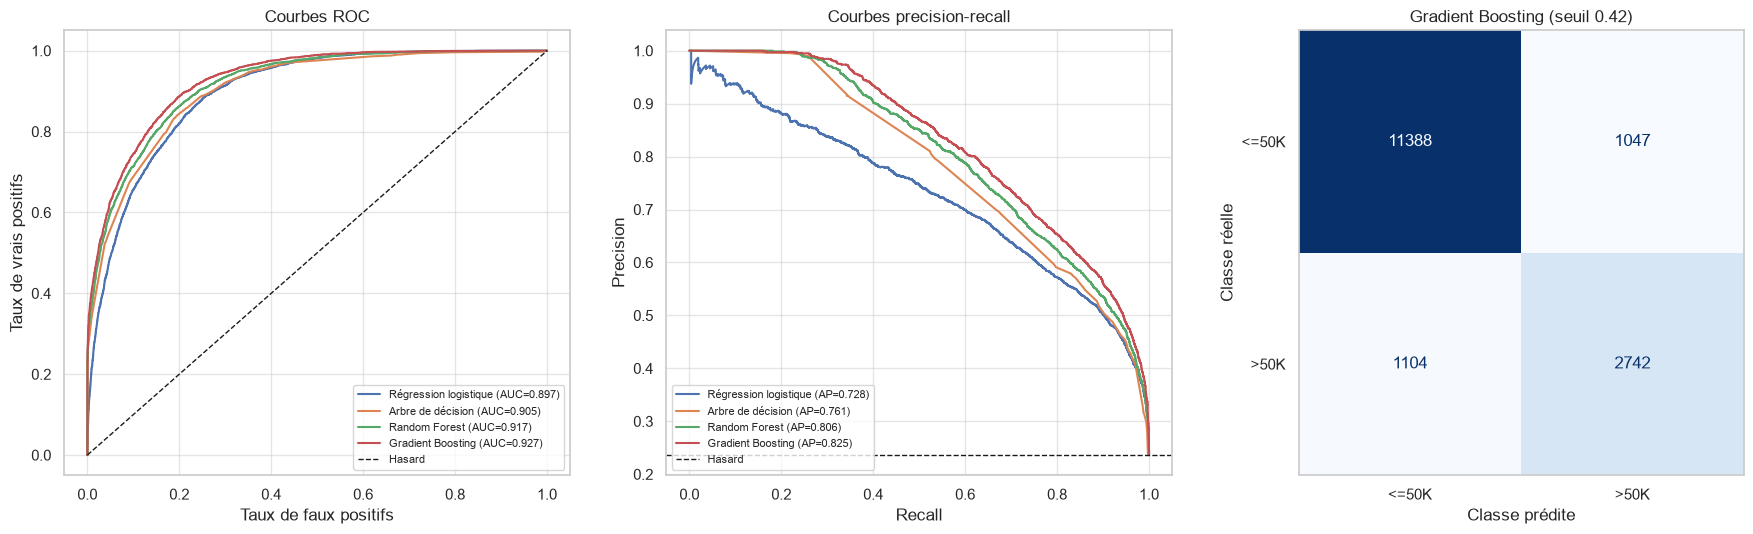

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
plot_roc_curves(test_scores, y_test, ax=axes[0])
plot_pr_curves(test_scores, y_test, ax=axes[1])
plot_confusion(y_test, y_pred, title=f"{best_name} (seuil {threshold:.2f})", ax=axes[2])
fig.tight_layout()
save(fig, "model_test_curves.png")

**Lecture**
- ROC-AUC de **0,927 sur le test** contre 0,929 en validation croisée : **pas de surapprentissage**,
  la performance se généralise.
- Le Gradient Boosting est premier sur toutes les métriques sans seuil (ROC-AUC 0,927,
  PR-AUC 0,825) et sur l'accuracy (0,873).
- La régression logistique a le meilleur recall (0,84) car le tuning a retenu
  `class_weight="balanced"`, mais au prix d'une precision faible (0,55) : beaucoup de fausses alertes.
- Abaisser le seuil de 0,5 à 0,42 fait passer le recall de 0,65 à 0,71 (on détecte plus de >50K)
  pour une precision de 0,77 → 0,72, et le F1 de 0,708 à 0,718. C'est un choix métier : que coûte
  un faux positif par rapport à un faux négatif ?

## 7. Interprétation : quelles variables comptent ?

**Importance par permutation** : on mélange une variable au hasard sur le jeu de test et on
mesure la perte de ROC-AUC. Méthode valable pour n'importe quel modèle, sur les variables d'origine.

,variable,importance,std
0,marital-status,0.0763,0.0011
1,capital-gain,0.0582,0.0014
2,age,0.0444,0.0015
3,education-num,0.0314,0.0012
4,capital-loss,0.0133,0.0005
5,hours-per-week,0.0120,0.0006
6,occupation,0.0115,0.0006
7,relationship,0.0048,0.0002
8,sex,0.0024,0.0002
9,workclass,0.0023,0.0001


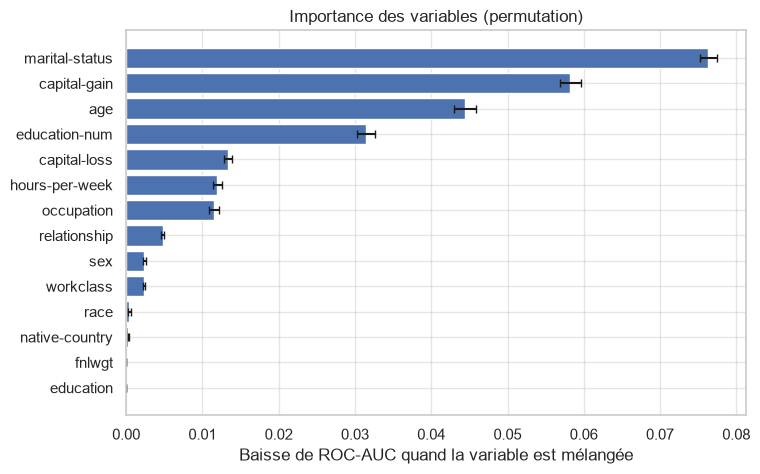

In [11]:
importances = permutation_importance_df(best_model, X_test, y_test, n_repeats=2 if FAST else 5)
fig, ax = plt.subplots(figsize=(8, 5))
plot_importance(importances, ax=ax)
save(fig, "model_permutation_importance.png")
importances.round(4)

Comparaison avec un modèle directement interprétable : les coefficients de la régression logistique.

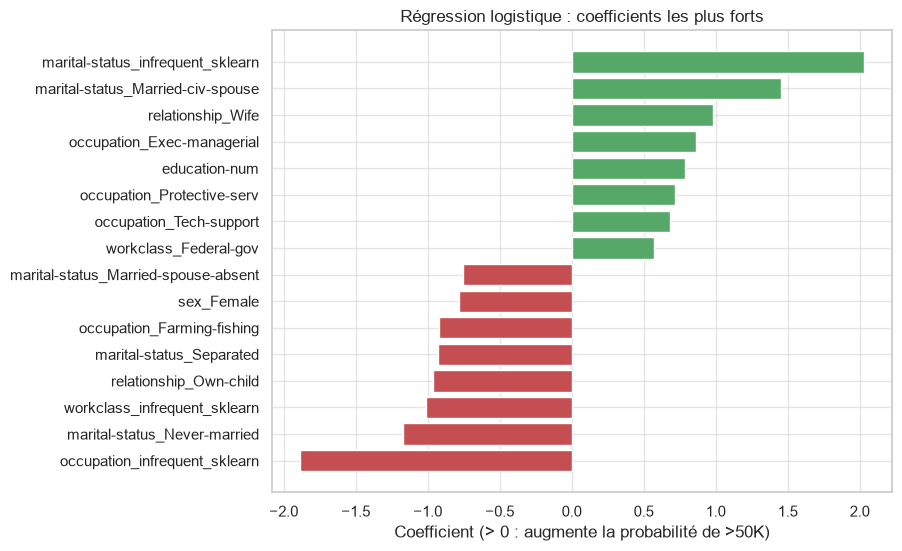

In [12]:
logreg = searches["Régression logistique"].best_estimator_
coefs = pd.Series(logreg.named_steps["model"].coef_[0],
                  index=logreg.named_steps["prep"].get_feature_names_out())
top = pd.concat([coefs.nlargest(8), coefs.nsmallest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#55A868", "#C44E52"))
ax.set(title="Régression logistique : coefficients les plus forts",
       xlabel="Coefficient (> 0 : augmente la probabilité de >50K)")
save(fig, "model_logreg_coefs.png")

## 8. Analyse d'équité (fairness)

Les données de 1994 contiennent de fortes inégalités de revenus selon le sexe et l'origine.
Un modèle entraîné sur ces données risque de les **reproduire**. On compare, par groupe :
- `taux_predit_50k` : part des personnes prédites >50K ;
- `tpr` (recall) : parmi les vrais >50K, part détectée ;
- `fpr` : parmi les vrais <=50K, part classée à tort >50K.

In [13]:
for col in SENSITIVE_FEATURES:
    print(f"--- {col} ---")
    display(fairness_report(y_test, y_pred, X_test[col]).round(3))

--- sex ---


,groupe,effectif,taux_reel_50k,taux_predit_50k,tpr,fpr,precision
0,Male,10860,0.300,0.301,0.725,0.119,0.722
1,Female,5421,0.109,0.096,0.649,0.029,0.732


--- race ---


,groupe,effectif,taux_reel_50k,taux_predit_50k,tpr,fpr,precision
0,White,13946,0.250,0.249,0.720,0.092,0.724
1,Black,1561,0.115,0.095,0.603,0.030,0.725
2,Asian-Pac-Islander,480,0.277,0.285,0.707,0.124,0.686
3,Amer-Indian-Eskimo,159,0.119,0.088,0.579,0.021,0.786
4,Other,135,0.185,0.126,0.600,0.018,0.882


**Lecture**
- **Sexe** : le modèle prédit >50K pour 30,1 % des hommes (30,0 % en réalité) et 9,6 % des femmes
  (10,9 % en réalité). Il **reproduit l'écart** des données et l'accentue légèrement pour les femmes.
- Il détecte moins bien les femmes à >50K (TPR 0,65 contre 0,72 pour les hommes) :
  l'« égalité des chances » n'est pas respectée.
- En revanche, la precision est identique (0,72 / 0,73) : quand le modèle prédit >50K,
  il a autant raison pour les deux sexes.
- **Origine** : même tendance, avec un TPR de 0,60 pour les personnes `Black` contre 0,72 pour
  `White`. Les petits groupes (`Amer-Indian-Eskimo`, `Other` : moins de 160 personnes) donnent des
  chiffres peu fiables.
- Retirer la variable `sex` ne suffirait pas : `relationship` (Husband / Wife) la contient
  indirectement (V de Cramér de 0,65). Pistes : seuils par groupe, rééquilibrage,
  bibliothèque `fairlearn`.

## 9. Conclusion : quel modèle et pourquoi ?

**Modèle retenu : Gradient Boosting** (`HistGradientBoostingClassifier`, 200 itérations,
taux d'apprentissage 0,1, 15 feuilles max, au moins 50 individus par feuille, régularisation L2 0,1),
avec un **seuil de décision de 0,42**.

| Critère | Gradient Boosting | Meilleure alternative |
|---|---|---|
| ROC-AUC (CV) | **0,929 ± 0,002** | Random Forest : 0,920 ± 0,002 |
| ROC-AUC (test) | **0,927** | Random Forest : 0,917 |
| PR-AUC (test) | **0,825** | Random Forest : 0,806 |
| F1 (test) | **0,718** (seuil 0,42) | Random Forest : 0,681 (seuil 0,5) |
| Temps d'entraînement | 2,5 s | Random Forest : 4,6 s |

Pourquoi ce modèle :
- **Performance** : premier sur toutes les métriques, en validation croisée comme sur le test.
- **Stabilité** : écart-type de 0,0015 entre les plis, et un score de test identique à la CV.
- **Coût** : plus rapide à entraîner que la Random Forest, prédiction instantanée.
- **Interprétabilité** : moins direct qu'une régression logistique, mais l'importance par
  permutation donne un classement cohérent avec l'EDA : statut marital, gains en capital, âge,
  niveau d'études.
- **Alternative** : la régression logistique est entièrement explicable (coefficients), mais perd
  3 points de ROC-AUC (0,897) et 10 points de PR-AUC. Le gain de performance justifie le boosting.

**Limites** :
- données de 1994, non représentatives d'aujourd'hui ;
- le modèle reproduit les inégalités de revenus selon le sexe et l'origine (section 8) ;
- le seuil de 0,42 optimise le F1 et doit être adapté à l'usage réel.

In [14]:
import json

from src.config import MODEL_META_PATH, MODEL_PATH

# Même format que `python -m src.models.train` : c'est ce fichier que charge l'API.
save_model(best_model, MODEL_PATH)
meta = {"modele": best_name, "hyperparametres": searches[best_name].best_params_,
        "seuil": threshold, "test": final.round(4).to_dict(orient="index")}
MODEL_META_PATH.write_text(json.dumps(meta, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(f"Modèle sauvegardé : {MODEL_PATH}")

Modèle sauvegardé : /Users/silviogangi/M2_SIAD/MLOPS/MLops_Gangi_Bart_Daoud/models/model.joblib
